In [1]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.


AQI MACHINE LEARNING PROJECT
FEATURE ENGINEERING, MODEL TRAINING AND EVALUATION

Current working directory:
C:\Users\HP

Dataset loaded successfully!
File: C:\Users\HP\processed\cleaned_aqi.csv
Dataset shape: (378328, 6)

Columns:
['Date', 'Month', 'City', 'AQI_Category', 'AQI', 'Pollutant']

Dataset prepared successfully!
Prepared shape: (148729, 3)
Number of cities: 304
Date range: 2020-01-01 00:00:00 to 2025-12-10 00:00:00

Date features created successfully!

Historical AQI features created successfully!

Final dataset shape: (146601, 16)

Selected features:
✓ City
✓ Year
✓ Month
✓ Day
✓ DayOfYear
✓ DayOfWeek
✓ Quarter
✓ Previous_AQI
✓ Previous_2_AQI
✓ Previous_3_AQI
✓ Previous_7_AQI
✓ Average_3
✓ Average_7
✓ Recent_Change

Target variable: AQI

Feature-engineered dataset saved:
C:\Users\HP\processed\feature_engineered_aqi.csv

TRAINING AND TESTING DATA

Training years:
[np.int32(2020), np.int32(2021), np.int32(2022), np.int32(2023), np.int32(2024)]

Testing years:
[np.int32(2025)]

,Model,MAE,RMSE,R2
0,XGBoost,26.698223,38.089287,0.448957
1,Gradient Boosting,27.206727,38.780141,0.428786
2,Random Forest,27.163037,39.558077,0.405639
3,Linear Regression,37.528252,50.219717,0.042082



Best model based on lowest RMSE:
XGBoost

BEST MODEL PERFORMANCE
----------------------
Model: XGBoost
MAE: 26.7
RMSE: 38.09
R2: 0.449


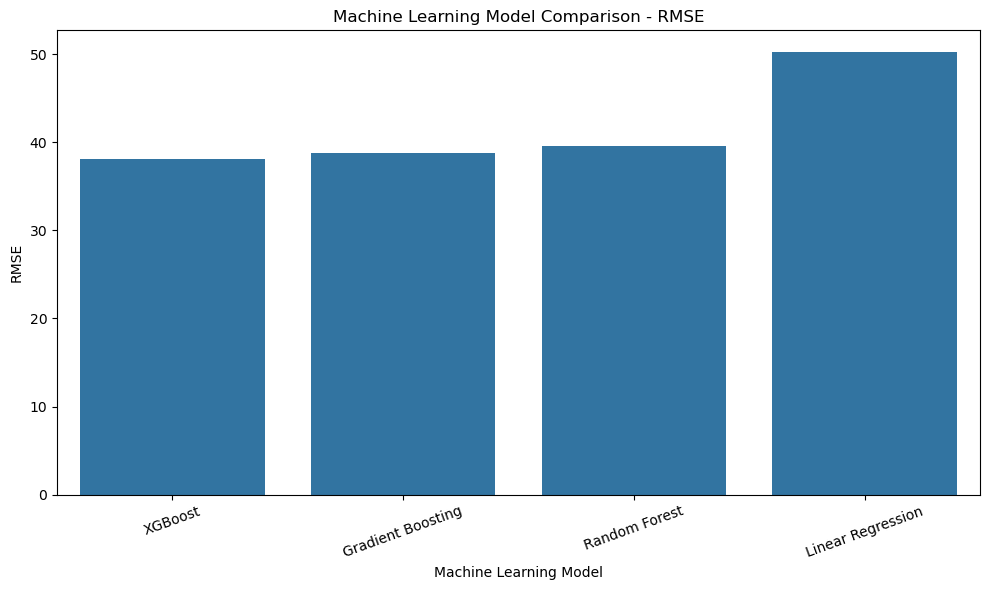

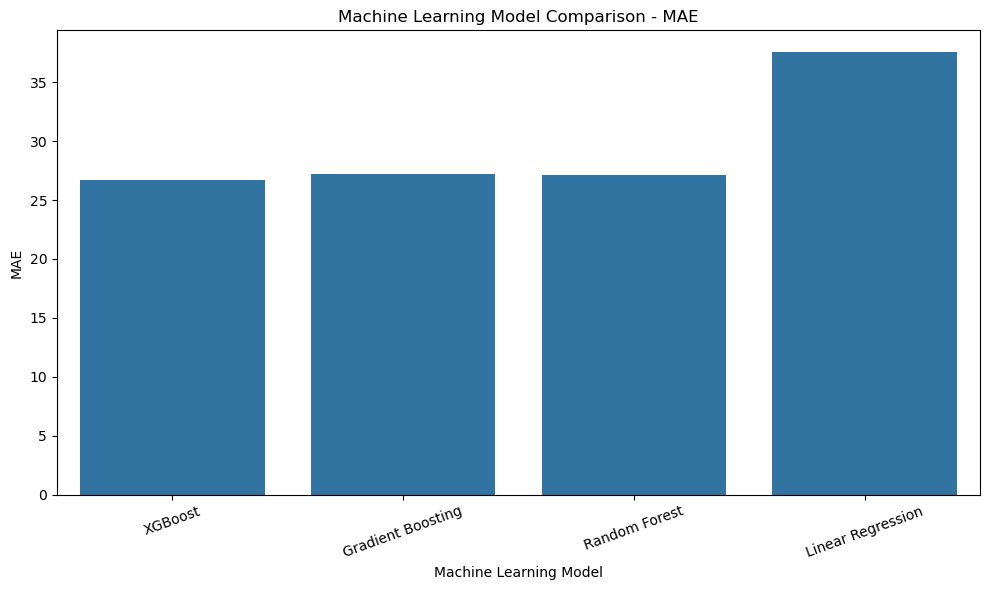

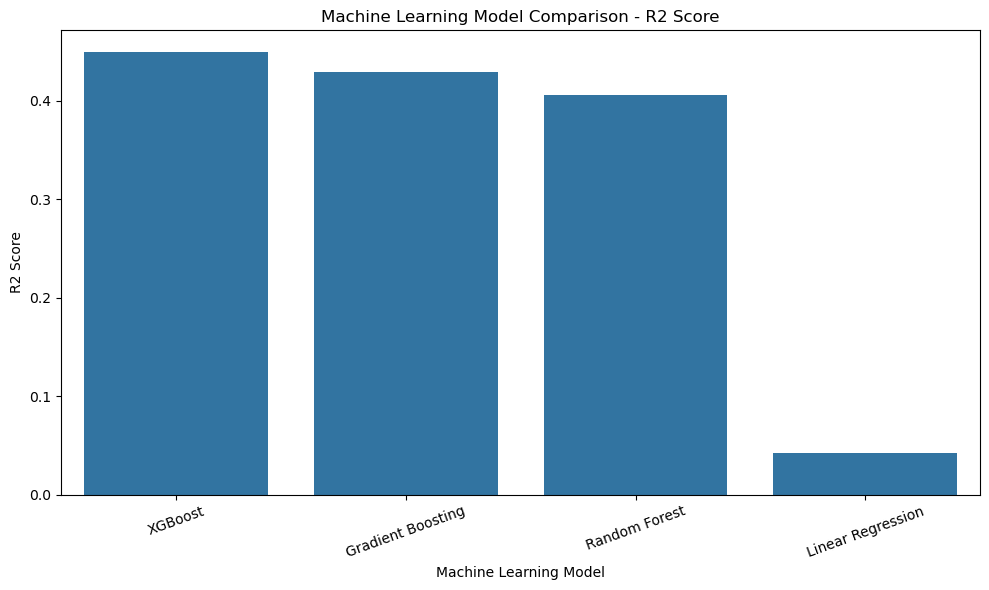

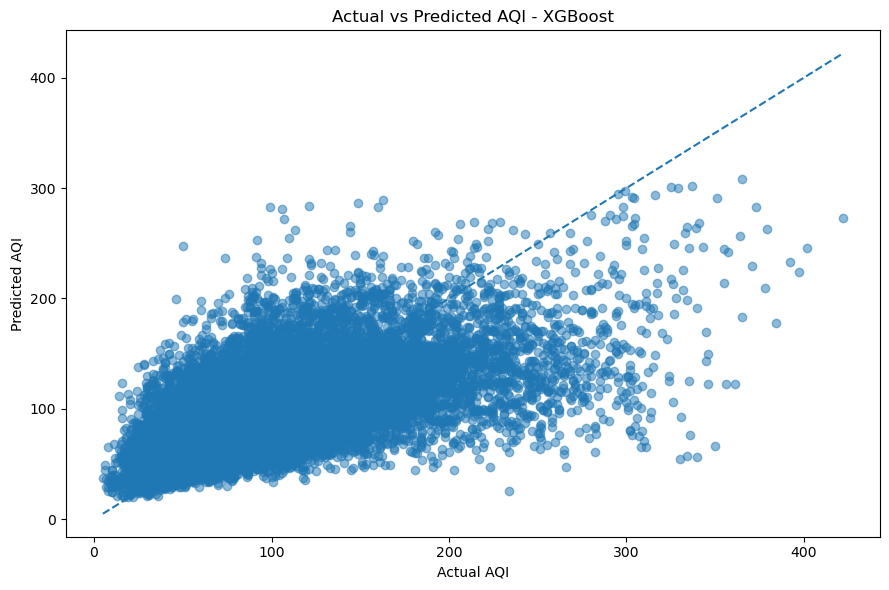


Sample prediction results:


,Date,City,Actual_AQI,Predicted_AQI,Error,Absolute_Error
0,2025-01-02,Agartala,62.0,159.919998,-97.919998,97.919998
1,2025-01-02,Agra,96.0,107.190002,-11.190002,11.190002
2,2025-01-02,Ahmedabad,112.0,116.360001,-4.360001,4.360001
3,2025-01-02,Ahmednagar,192.0,119.000000,73.000000,73.000000
4,2025-01-02,Aizawl,95.0,64.750000,30.250000,30.250000
5,2025-01-02,Ajmer,106.0,102.019997,3.980003,3.980003
6,2025-01-02,Akola,109.0,100.779999,8.220001,8.220001
7,2025-01-02,Alwar,106.0,93.760002,12.239998,12.239998
8,2025-01-02,Amaravati,43.0,104.349998,-61.349998,61.349998
9,2025-01-02,Amravati,136.0,95.550003,40.449997,40.449997


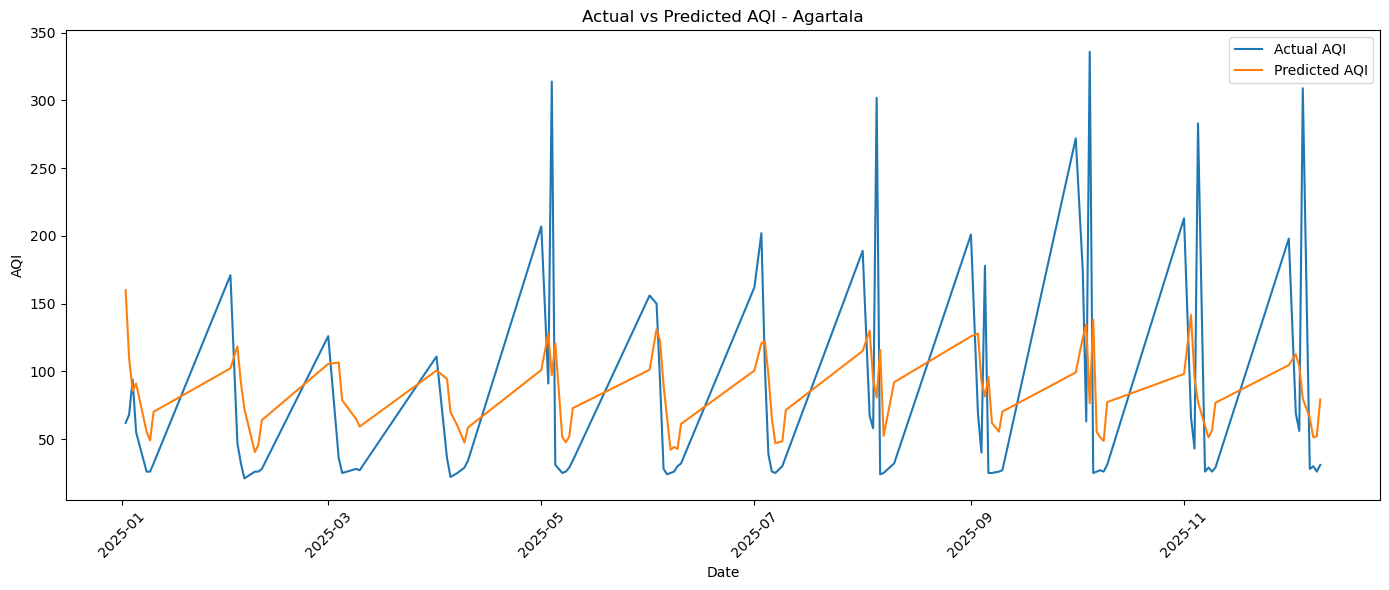

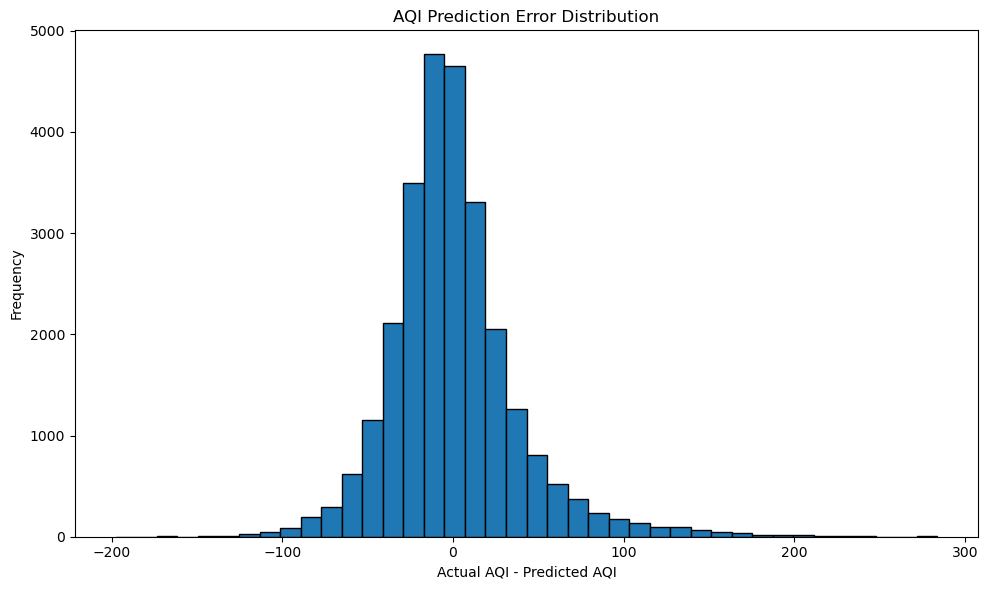


Top 20 Important Features:


,Feature,Importance
305,numeric__Previous_AQI,0.043895
301,numeric__Day,0.029213
309,numeric__Average_3,0.024915
310,numeric__Average_7,0.017648
285,categorical__City_Vapi,0.012925
194,categorical__City_Muzaffarpur,0.011802
28,categorical__City_Balasore,0.010548
287,categorical__City_Vatva,0.010468
116,categorical__City_Hapur,0.010174
140,categorical__City_Kaithal,0.010039


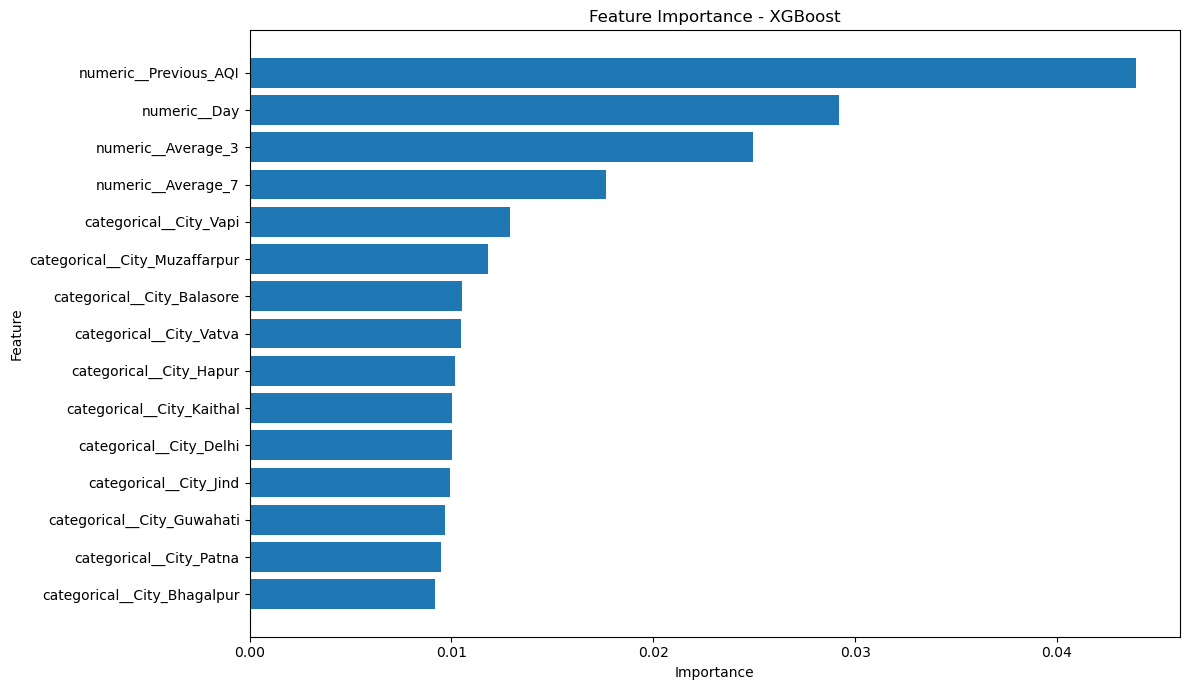


Model evaluation results saved:
C:\Users\HP\processed\model_evaluation_results.csv

Prediction results saved:
C:\Users\HP\processed\model_predictions_2025.csv

Feature importance saved:
C:\Users\HP\processed\feature_importance.csv

Complete best model pipeline saved!
C:\Users\HP\models\aqi_model.pkl

Preprocessor saved!
C:\Users\HP\models\encoders.pkl

Saved model verification:
Original RMSE: 38.0893
Loaded model RMSE: 38.0893
Model verification: Successful

AQI MACHINE LEARNING COMPLETED SUCCESSFULLY

Dataset:
AQI 2020-2025

Training Period:
2020-2024

Testing Period:
2025

Models Evaluated:
✓ XGBoost
✓ Gradient Boosting
✓ Random Forest
✓ Linear Regression

Best Model:
XGBoost

Best Model Metrics:
MAE : 26.7
RMSE: 38.09
R2  : 0.449

Saved Files:
1. C:\Users\HP\processed\feature_engineered_aqi.csv
2. C:\Users\HP\processed\model_evaluation_results.csv
3. C:\Users\HP\processed\model_predictions_2025.csv
4. C:\Users\HP\models\aqi_model.pkl
5. C:\Users\HP\models\encoders.pkl

ALL OPERATIO

In [2]:
import os
import warnings
import joblib

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

warnings.filterwarnings("ignore")

print("=" * 65)
print("AQI MACHINE LEARNING PROJECT")
print("FEATURE ENGINEERING, MODEL TRAINING AND EVALUATION")
print("=" * 65)

print("\nCurrent working directory:")
print(os.getcwd())

BASE_DIR = os.getcwd()

PROCESSED_DIR = os.path.join(
    BASE_DIR, "processed"
)

MODELS_DIR = os.path.join(
    BASE_DIR, "models"
)

os.makedirs(PROCESSED_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)

possible_paths = [
    os.path.join(PROCESSED_DIR, "cleaned_aqi.csv"),
    os.path.join(BASE_DIR, "cleaned_aqi.csv"),
    os.path.join(BASE_DIR, "data", "processed", "cleaned_aqi.csv")
]

input_path = next(
    (path for path in possible_paths if os.path.exists(path)),
    None
)

if input_path is None:
    raise FileNotFoundError(
        "cleaned_aqi.csv not found. "
        "Place it inside the processed folder or "
        "the current working directory."
    )

df = pd.read_csv(input_path)

print("\nDataset loaded successfully!")
print("File:", input_path)
print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

required_columns = ["Date", "City", "AQI"]

for col in required_columns:
    if col not in df.columns:
        raise ValueError(
            f"Required column missing: {col}"
        )

# Convert data types
df["Date"] = pd.to_datetime(
    df["Date"],
    errors="coerce",
    dayfirst=True
)

df["AQI"] = pd.to_numeric(
    df["AQI"],
    errors="coerce"
)

df["City"] = df["City"].astype("string").str.strip()

# Remove invalid records
df = df.dropna(
    subset=["Date", "City", "AQI"]
).copy()

df = df[
    (df["City"] != "") &
    (df["AQI"] >= 0)
].copy()

# Standardize city names
df["City"] = df["City"].astype(str)

# Sort data
df = df.sort_values(
    ["City", "Date"]
).reset_index(drop=True)

df = (
    df.groupby(
        ["City", "Date"],
        as_index=False
    )
    .agg(
        AQI=("AQI", "mean")
    )
)

df = df.sort_values(
    ["City", "Date"]
).reset_index(drop=True)

print("\nDataset prepared successfully!")
print("Prepared shape:", df.shape)
print("Number of cities:", df["City"].nunique())
print("Date range:", df["Date"].min(), "to", df["Date"].max())

df["Year"] = df["Date"].dt.year

df["Month"] = df["Date"].dt.month

df["Day"] = df["Date"].dt.day

df["DayOfYear"] = df["Date"].dt.dayofyear

df["DayOfWeek"] = df["Date"].dt.dayofweek

df["Quarter"] = df["Date"].dt.quarter

print("\nDate features created successfully!")

# Calculate historical features separately for each city.

grouped_aqi = df.groupby("City")["AQI"]

# Previous AQI readings
df["Previous_AQI"] = grouped_aqi.shift(1)

df["Previous_2_AQI"] = grouped_aqi.shift(2)

df["Previous_3_AQI"] = grouped_aqi.shift(3)

df["Previous_7_AQI"] = grouped_aqi.shift(7)

# Previous 3-reading average
df["Average_3"] = grouped_aqi.transform(
    lambda x: x.shift(1).rolling(
        window=3,
        min_periods=3
    ).mean()
)

# Previous 7-reading average
df["Average_7"] = grouped_aqi.transform(
    lambda x: x.shift(1).rolling(
        window=7,
        min_periods=7
    ).mean()
)

# Recent AQI change
df["Recent_Change"] = (
    df["Previous_AQI"] -
    df["Previous_2_AQI"]
)

print("\nHistorical AQI features created successfully!")

features = [
    "City",
    "Year",
    "Month",
    "Day",
    "DayOfYear",
    "DayOfWeek",
    "Quarter",
    "Previous_AQI",
    "Previous_2_AQI",
    "Previous_3_AQI",
    "Previous_7_AQI",
    "Average_3",
    "Average_7",
    "Recent_Change"
]

target = "AQI"

# Remove rows without sufficient historical readings
df = df.dropna(
    subset=features + [target]
).copy()

df = df.sort_values(
    ["Date", "City"]
).reset_index(drop=True)

print("\nFinal dataset shape:", df.shape)

print("\nSelected features:")
for feature in features:
    print("✓", feature)

print("\nTarget variable:", target)

feature_data_path = os.path.join(
    PROCESSED_DIR,
    "feature_engineered_aqi.csv"
)

df.to_csv(
    feature_data_path,
    index=False
)

print("\nFeature-engineered dataset saved:")
print(feature_data_path)

# Training: 2020 to 2024
# Testing: 2025

train = df[
    df["Year"] <= 2024
].copy()

test = df[
    df["Year"] == 2025
].copy()

if train.empty:
    raise ValueError(
        "No training records found for 2020-2024."
    )

if test.empty:
    raise ValueError(
        "No testing records found for 2025. "
        "Check your dataset date range."
    )

print("\n" + "=" * 65)
print("TRAINING AND TESTING DATA")
print("=" * 65)

print("\nTraining years:")
print(sorted(train["Year"].unique()))

print("\nTesting years:")
print(sorted(test["Year"].unique()))

print("\nTraining records:", len(train))
print("Testing records:", len(test))

X_train = train[features].copy()

X_test = test[features].copy()

y_train = train[target].copy()

y_test = test[target].copy()

print("\nX_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

categorical_features = [
    "City"
]

numeric_features = [
    "Year",
    "Month",
    "Day",
    "DayOfYear",
    "DayOfWeek",
    "Quarter",
    "Previous_AQI",
    "Previous_2_AQI",
    "Previous_3_AQI",
    "Previous_7_AQI",
    "Average_3",
    "Average_7",
    "Recent_Change"
]

def create_preprocessor():

    # Support both newer and older sklearn versions
    try:
        encoder = OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        )

    except TypeError:
        encoder = OneHotEncoder(
            handle_unknown="ignore",
            sparse=False
        )

    categorical_transformer = Pipeline(
        steps=[
            (
                "imputer",
                SimpleImputer(
                    strategy="most_frequent"
                )
            ),
            (
                "encoder",
                encoder
            )
        ]
    )

    numeric_transformer = Pipeline(
        steps=[
            (
                "imputer",
                SimpleImputer(
                    strategy="median"
                )
            )
        ]
    )

    preprocessor = ColumnTransformer(
        transformers=[
            (
                "categorical",
                categorical_transformer,
                categorical_features
            ),
            (
                "numeric",
                numeric_transformer,
                numeric_features
            )
        ]
    )

    return preprocessor
    
def create_model_pipeline(regressor):

    pipeline = Pipeline(
        steps=[
            (
                "preprocessor",
                create_preprocessor()
            ),
            (
                "regressor",
                regressor
            )
        ]
    )

    return pipeline


models = {

    "Linear Regression":
        LinearRegression(),

    "Random Forest":
        RandomForestRegressor(
            n_estimators=200,
            max_features=0.9,
            random_state=42,
            n_jobs=-1
        ),

    "Gradient Boosting":
        GradientBoostingRegressor(
            n_estimators=200,
            learning_rate=0.05,
            max_depth=3,
            random_state=42
        )
}


# Add XGBoost if installed
try:

    from xgboost import XGBRegressor

    models["XGBoost"] = XGBRegressor(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    )

    print("\nXGBoost is available.")

except ImportError:

    print("\nXGBoost is not installed.")
    print("Install using: %pip install xgboost")


trained_models = {}

all_predictions = {}

results_list = []

for model_name, regressor in models.items():

    print("\n" + "=" * 65)
    print("TRAINING:", model_name)
    print("=" * 65)

    pipeline = create_model_pipeline(regressor)

    # Train model
    pipeline.fit(
        X_train,
        y_train
    )

    # Predict AQI
    predictions = pipeline.predict(
        X_test
    )

    # Calculate evaluation metrics
    mae = mean_absolute_error(
        y_test,
        predictions
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_test,
            predictions
        )
    )

    r2 = r2_score(
        y_test,
        predictions
    )

    # Store trained model
    trained_models[model_name] = pipeline

    all_predictions[model_name] = predictions

    # Store actual metrics
    results_list.append({
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

    print("\nTraining completed!")
    print("MAE :", round(mae, 2))
    print("RMSE:", round(rmse, 2))
    print("R2  :", round(r2, 4))

results = pd.DataFrame(results_list)

results_sorted = (
    results.sort_values(
        by="RMSE",
        ascending=True
    )
    .reset_index(drop=True)
)

print("\n" + "=" * 65)
print("FINAL MODEL COMPARISON")
print("=" * 65)

display(results_sorted)

best_model_name = results_sorted.loc[
    0, "Model"
]

best_model = trained_models[
    best_model_name
]

best_predictions = all_predictions[
    best_model_name
]

print("\nBest model based on lowest RMSE:")
print(best_model_name)

best_result = results_sorted.iloc[0]

print("\nBEST MODEL PERFORMANCE")
print("----------------------")

print("Model:", best_model_name)

print("MAE:", round(best_result["MAE"], 2))

print("RMSE:", round(best_result["RMSE"], 2))

print("R2:", round(best_result["R2"], 4))


# RMSE comparison
plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_sorted,
    x="Model",
    y="RMSE"
)

plt.title("Machine Learning Model Comparison - RMSE")
plt.xlabel("Machine Learning Model")
plt.ylabel("RMSE")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


# MAE comparison
plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_sorted,
    x="Model",
    y="MAE"
)

plt.title("Machine Learning Model Comparison - MAE")
plt.xlabel("Machine Learning Model")
plt.ylabel("MAE")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


# R2 comparison
plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_sorted,
    x="Model",
    y="R2"
)

plt.title("Machine Learning Model Comparison - R2 Score")
plt.xlabel("Machine Learning Model")
plt.ylabel("R2 Score")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 6))

plt.scatter(
    y_test,
    best_predictions,
    alpha=0.5
)

minimum = min(
    y_test.min(),
    best_predictions.min()
)

maximum = max(
    y_test.max(),
    best_predictions.max()
)

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.title(
    f"Actual vs Predicted AQI - {best_model_name}"
)

plt.xlabel("Actual AQI")
plt.ylabel("Predicted AQI")

plt.tight_layout()
plt.show()


prediction_results = pd.DataFrame({

    "Date": test["Date"].values,

    "City": test["City"].values,

    "Actual_AQI": y_test.values,

    "Predicted_AQI": best_predictions

})

prediction_results["Predicted_AQI"] = (
    prediction_results["Predicted_AQI"].round(2)
)

prediction_results["Error"] = (
    prediction_results["Actual_AQI"] -
    prediction_results["Predicted_AQI"]
)

prediction_results["Absolute_Error"] = (
    prediction_results["Error"].abs()
)

print("\nSample prediction results:")

display(
    prediction_results.head(15)
)

# Select a city with test records for a readable
# single-city chronological graph.

available_test_cities = sorted(
    prediction_results["City"].unique()
)

selected_plot_city = available_test_cities[0]

city_predictions = prediction_results[
    prediction_results["City"] == selected_plot_city
].sort_values("Date")

plt.figure(figsize=(14, 6))

plt.plot(
    city_predictions["Date"],
    city_predictions["Actual_AQI"],
    label="Actual AQI"
)

plt.plot(
    city_predictions["Date"],
    city_predictions["Predicted_AQI"],
    label="Predicted AQI"
)

plt.title(
    f"Actual vs Predicted AQI - {selected_plot_city}"
)

plt.xlabel("Date")
plt.ylabel("AQI")

plt.legend()
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 6))

plt.hist(
    prediction_results["Error"],
    bins=40,
    edgecolor="black"
)

plt.title("AQI Prediction Error Distribution")

plt.xlabel("Actual AQI - Predicted AQI")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()


trained_regressor = best_model.named_steps[
    "regressor"
]

fitted_preprocessor = best_model.named_steps[
    "preprocessor"
]

if hasattr(
    trained_regressor,
    "feature_importances_"
):

    importances = (
        trained_regressor.feature_importances_
    )

    feature_names = (
        fitted_preprocessor.get_feature_names_out()
    )

    importance_df = pd.DataFrame({

        "Feature": feature_names,

        "Importance": importances

    })

    importance_df = importance_df.sort_values(
        "Importance",
        ascending=False
    )

    print("\nTop 20 Important Features:")

    display(
        importance_df.head(20)
    )

    top_features = (
        importance_df.head(15)
        .sort_values("Importance")
    )

    plt.figure(figsize=(12, 7))

    plt.barh(
        top_features["Feature"],
        top_features["Importance"]
    )

    plt.title(
        f"Feature Importance - {best_model_name}"
    )

    plt.xlabel("Importance")
    plt.ylabel("Feature")

    plt.tight_layout()
    plt.show()

elif hasattr(
    trained_regressor,
    "coef_"
):

    feature_names = (
        fitted_preprocessor.get_feature_names_out()
    )

    importance_df = pd.DataFrame({

        "Feature": feature_names,

        "Coefficient": trained_regressor.coef_,

        "Importance": np.abs(
            trained_regressor.coef_
        )

    })

    importance_df = importance_df.sort_values(
        "Importance",
        ascending=False
    )

    print("\nTop 20 Important Features:")

    display(
        importance_df.head(20)
    )

else:

    importance_df = pd.DataFrame()

    print(
        "\nFeature importance is not available "
        "for this model."
    )


# ==============================================================
# 25. SAVE MODEL COMPARISON RESULTS
# ==============================================================

results_path = os.path.join(
    PROCESSED_DIR,
    "model_evaluation_results.csv"
)

results_sorted.to_csv(
    results_path,
    index=False
)

print("\nModel evaluation results saved:")
print(results_path)

prediction_path = os.path.join(
    PROCESSED_DIR,
    "model_predictions_2025.csv"
)

prediction_results.to_csv(
    prediction_path,
    index=False
)

print("\nPrediction results saved:")
print(prediction_path)

if not importance_df.empty:

    importance_path = os.path.join(
        PROCESSED_DIR,
        "feature_importance.csv"
    )

    importance_df.to_csv(
        importance_path,
        index=False
    )

    print("\nFeature importance saved:")
    print(importance_path)


# The pipeline includes:
# 1. Missing-value imputation
# 2. City One-Hot Encoding
# 3. Numerical feature processing
# 4. Trained machine learning model

model_path = os.path.join(
    MODELS_DIR,
    "aqi_model.pkl"
)

joblib.dump(
    best_model,
    model_path
)

print("\nComplete best model pipeline saved!")
print(model_path)

encoder_path = os.path.join(
    MODELS_DIR,
    "encoders.pkl"
)

joblib.dump(
    fitted_preprocessor,
    encoder_path
)

print("\nPreprocessor saved!")
print(encoder_path)


loaded_model = joblib.load(
    model_path
)

loaded_predictions = loaded_model.predict(
    X_test
)

loaded_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        loaded_predictions
    )
)

print("\nSaved model verification:")

print(
    "Original RMSE:",
    round(best_result["RMSE"], 4)
)

print(
    "Loaded model RMSE:",
    round(loaded_rmse, 4)
)

print(
    "Model verification:",
    "Successful" if np.isclose(
        loaded_rmse,
        best_result["RMSE"]
    ) else "Check required"
)

print("\n" + "=" * 65)
print("AQI MACHINE LEARNING COMPLETED SUCCESSFULLY")
print("=" * 65)

print("\nDataset:")
print("AQI 2020-2025")

print("\nTraining Period:")
print("2020-2024")

print("\nTesting Period:")
print("2025")

print("\nModels Evaluated:")

for name in results_sorted["Model"]:
    print("✓", name)

print("\nBest Model:")
print(best_model_name)

print("\nBest Model Metrics:")
print("MAE :", round(best_result["MAE"], 2))
print("RMSE:", round(best_result["RMSE"], 2))
print("R2  :", round(best_result["R2"], 4))

print("\nSaved Files:")

print("1.", feature_data_path)
print("2.", results_path)
print("3.", prediction_path)
print("4.", model_path)
print("5.", encoder_path)

print("\n" + "=" * 65)
print("ALL OPERATIONS COMPLETED")
print("=" * 65)
